**Group 35 — AT2 Notebook 4**

**Member:** Zongliang Han  
**Student ID:** 14739080  
**Technique:** Undercomplete autoencoder + regression head (Lab 8)


**Shared code.** Data preparation, the training loop and the plots come from `bike_common.py`, the group's shared module, so that all four methods use identical rows, features and metrics; calls to it appear as `bc.<function>`. The Canvas portal accepts only notebook files, so the source code of **every `bike_common` function this notebook calls is reproduced in the Appendix at the end of this notebook**. The full module is published at https://github.com/peterhanhhh-cyber/group35-bike-sharing-at2/blob/main/project/src/bike_common.py. All outputs are saved; the notebook does not need to be re-run to be assessed.

# 04 — Autoencoder + regression head (Zongliang Han, Lab 8)

**Question:** does a compressed representation of the 23 features help a
small regressor predict rentals?

**Method:** an undercomplete autoencoder (`23 → 16 → bottleneck → 16 → 23`)
learns to rebuild its input through a narrow bottleneck. The encoder is then
frozen and a small head (`bottleneck → 32 → 1`) predicts `cnt`.

**Fair test:** the same head trained on the raw 23 features ("raw MLP") and
ridge regression are controls. If AE + head does not beat the raw MLP, the
compression did not help — a **negative result** we report, not hide.

| Section | What it shows |
|---|---|
| 1 | Load the shared data |
| 2 | Autoencoder, head and training |
| 3 | Bottleneck search (4 / 8 / 12) and controls |
| 4 | Selected AE + head |
| 5 | Validation / test results and diagnostics |
| 6 | Cost and saved evidence |
| 7 | Conclusion |

## 1. Setup

**Data pipeline at a glance** (what `bike_common` does before any model sees the data):

1. reads `hour.csv` and rebuilds a complete hourly calendar — the 165 missing hours are added back;
2. forward-fills weather and past demand from earlier hours only; `cnt` stays empty at missing hours, so it is never a target;
3. builds the 23 shared features: one-hot season and weather, sin/cos month, hour and weekday, holiday and working-day flags, four weather values, and `lag1`, `lag24`, `lag168`, `roll24`, `roll168`;
4. assigns the frozen split (train → 2012-05-25, validation → 2012-09-12, test → 2012-12-31) and drops the two-week warm-up;
5. fits the scaler on training rows only.

`prepare_tabular()` returns one row per hour; `prepare_sequences(window)` returns the same rows as sliding windows.

In [1]:
import sys, time, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
# torch pieces, plus copy and time used by the training loop below
import torch.nn as nn

# probe for bike_common.py so the notebook runs from the repo root or src/
for p in [Path.cwd(), *Path.cwd().parents]:            # locate the shared module
    hits = [q for q in (p, p / "src", p / "code" / "src") if (q / "bike_common.py").exists()]
    if hits:
        sys.path.insert(0, str(hits[0]))
        break
import bike_common as bc

# shared plot style and seed
bc.setup_plot_style()
SEED = bc.SEED
# seed both libraries; the data loader is seeded separately
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

# design matrix: 23 features, frozen chronological split
d = bc.prepare_tabular()
# float32 arrays so torch does not copy them again
Xtr, Xva, Xte = (d[k].astype(np.float32) for k in ("X_train", "X_validation", "X_test"))
ytr, yva, yte = d["y_train"], d["y_validation"], d["y_test"]
# target scaling from the training split only
y_mean, y_std = float(ytr.mean()), float(ytr.std())
print(f"Rows: train {len(Xtr):,} | validation {len(Xva):,} | test {len(Xte):,}")

Rows: train 11,816 | validation 2,640 | test 2,600


## 2. Models and training
* Autoencoder: trained to minimise reconstruction MSE, early stopping on
  validation reconstruction loss (patience 10).
* Head: trained with the shared loop (`bc.train_regressor`), early stopping
  on validation MAE; no clipping or scheduler, as in the original design.

In [2]:
# symmetric autoencoder: 23 to 16 to bottleneck and back
class Autoencoder(nn.Module):
    def __init__(self, input_size, bottleneck, hidden=16):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_size, hidden), nn.ReLU(),
                                     nn.Linear(hidden, bottleneck))
        self.decoder = nn.Sequential(nn.Linear(bottleneck, hidden), nn.ReLU(),
                                     nn.Linear(hidden, input_size))

    def forward(self, x):
        z = self.encoder(x)
        # return both outputs: the head only needs the bottleneck
        return self.decoder(z), z


# the same head can sit on the bottleneck or on raw features
class RegressionHead(nn.Module):
    def __init__(self, input_size, hidden=32, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(input_size, hidden), nn.ReLU(),
                                 nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, x):
        # a single demand value per row
        return self.net(x)


# manual training loop: early stopping on validation reconstruction loss
def train_autoencoder(bottleneck, max_epochs=120, patience=10):
    torch.manual_seed(SEED)
    model = Autoencoder(Xtr.shape[1], bottleneck)
    # AdamW with a small weight decay keeps the bottleneck from exploding
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.MSELoss()
    Xtr_t, Xva_t = torch.tensor(Xtr), torch.tensor(Xva)
    # seeded generator so the shuffle order repeats
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xtr_t), batch_size=128,
                                         shuffle=True, generator=torch.Generator().manual_seed(SEED))
    history, best_loss, bad = [], float("inf"), 0
    best_state = copy.deepcopy(model.state_dict())
    t0 = time.perf_counter()
    # one epoch: training pass, then a validation pass
    for epoch in range(1, max_epochs + 1):
        model.train()
        running = 0.0
        for (xb,) in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb)[0], xb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xva_t)[0], Xva_t).item()
        history.append({"epoch": epoch, "train_loss": running / len(Xtr_t), "val_loss": val_loss})
        # keep the best weights instead of the last ones
        if val_loss < best_loss - 1e-5:
            best_loss, bad, best_state = val_loss, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                break
    # restore the best epoch before returning
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), time.perf_counter() - t0


# no gradients here: encoding is inference only
def encode(ae, X):
    with torch.no_grad():
        return ae.encoder(torch.tensor(X)).numpy()


# head training uses the shared regressor with clipping and scheduler off
def train_head(Ztr, Zva):
    return bc.train_regressor(lambda: RegressionHead(Ztr.shape[1]), Ztr, ytr, Zva, yva,
                              y_mean, y_std, max_epochs=100, patience=10,
                              clip=False, use_scheduler=False, verbose=False)

## 3. Bottleneck search and controls
Selection uses the **head's validation MAE**, not reconstruction loss: the
question is whether the code is useful for prediction.

In [3]:
# bottleneck search: 4, 8 and 12 latent dimensions
rows, models = [], {}
# each bottleneck is trained end to end: encoder then head
for b in (4, 8, 12):
    ae, ae_hist, ae_sec = train_autoencoder(b)
    head = train_head(encode(ae, Xtr), encode(ae, Xva))
    rows.append({"bottleneck": b, "ae_val_recon_loss": float(ae_hist["val_loss"].iloc[-1]),
                 "ae_seconds": ae_sec, "head_val_MAE": head["best_val_MAE"],
                 "head_seconds": head["train_seconds"],
                 "total_seconds": ae_sec + head["train_seconds"]})
    models[b] = {"ae": ae, "head": head["model"], "ae_history": ae_hist}
bottleneck_table = pd.DataFrame(rows)

raw = train_head(Xtr, Xva)                              # same head, raw features
from sklearn.linear_model import Ridge
# control 2: ridge on the raw features
ridge = Ridge(alpha=1.0, random_state=SEED).fit(Xtr, ytr)
print(f"Raw MLP validation MAE {raw['best_val_MAE']:.2f} | "
      f"ridge {bc.regression_metrics(yva, ridge.predict(Xva))['MAE']:.2f}")
# side-by-side table: reconstruction loss and downstream MAE
bottleneck_table.round(3)

model: early stop at epoch 27 (best epoch 17, MAE 61.84)


model: early stop at epoch 52 (best epoch 42, MAE 54.96)


model: early stop at epoch 50 (best epoch 40, MAE 56.10)


model: early stop at epoch 96 (best epoch 86, MAE 37.04)
Raw MLP validation MAE 37.04 | ridge 53.85


,bottleneck,ae_val_recon_loss,ae_seconds,head_val_MAE,head_seconds,total_seconds
0,4,0.392,14.572,61.837,5.411,19.984
1,8,0.315,8.659,54.957,10.317,18.976
2,12,0.134,17.920,56.098,9.961,27.881


## 4. Selected AE + head

In [4]:
# choose by validation MAE of the head, not by reconstruction loss
best_row = bottleneck_table.sort_values("head_val_MAE").iloc[0]
best_b = int(best_row["bottleneck"])
best_ae, best_head = models[best_b]["ae"], models[best_b]["head"]
ae_val_mae, raw_mae = float(best_row["head_val_MAE"]), raw["best_val_MAE"]
# report the gap against the control openly
print(f"Selected bottleneck {best_b}: validation MAE {ae_val_mae:.2f} vs raw MLP {raw_mae:.2f} "
      f"→ {'better' if ae_val_mae < raw_mae else 'worse'} than the control")

Selected bottleneck 8: validation MAE 54.96 vs raw MLP 37.04 → worse than the control


## 5. Results
All three models are evaluated on test once, so the negative / positive
result is visible on data not used for any decision.

In [5]:
# encode first, then apply the head; both are trained
def ae_predict(X):
    return bc.predict_regressor(best_head, encode(best_ae, X.astype(np.float32)), y_mean, y_std)


# three candidates on both splits
preds = {"AE + head": (ae_predict(Xva), ae_predict(Xte)),
         "raw MLP": (bc.predict_regressor(raw["model"], Xva, y_mean, y_std),
                     bc.predict_regressor(raw["model"], Xte, y_mean, y_std)),
         "ridge": (ridge.predict(Xva), ridge.predict(Xte))}
# identical metric bundle for every candidate
metrics = {n: {"validation": bc.regression_metrics(yva, v), "test": bc.regression_metrics(yte, t)}
           for n, (v, t) in preds.items()}
display(pd.DataFrame({n: {f"{s} {m}": v[s][m] for s in ("validation", "test")
                          for m in ("MAE", "RMSE", "R2")} for n, v in metrics.items()}).T.round(3))

ae_val_pred, ae_test_pred = preds["AE + head"]
ev = bc.evaluate(yva, ae_val_pred, yte, ae_test_pred, d["validation"], d["test"], d["train"])
bc.scenario_table(ev)

,validation MAE,validation RMSE,validation R2,test MAE,test RMSE,test R2
AE + head,54.957,82.152,0.865,58.472,85.624,0.840
raw MLP,37.041,57.333,0.934,33.752,54.479,0.935
ridge,53.848,79.318,0.874,51.410,77.676,0.869


Validation: MAE 54.96 | RMSE 82.15 | R2 0.8650
Test:       MAE 58.47 | RMSE 85.62 | R2 0.8403


,validation n,validation MAE,test n,test MAE
peak_hours,660,87.19,653,92.85
off_peak_hours,1980,44.21,1947,46.94
weekday,1800,56.74,1737,60.47
weekend_or_holiday,840,51.14,863,54.44
high_demand,1381,73.37,1055,87.44
lower_demand,1259,34.76,1545,38.69


**Autoencoder diagnostics.** The reconstruction-loss curve shows when the encoder stopped improving; the PCA scatter shows whether the bottleneck keeps the demand structure.


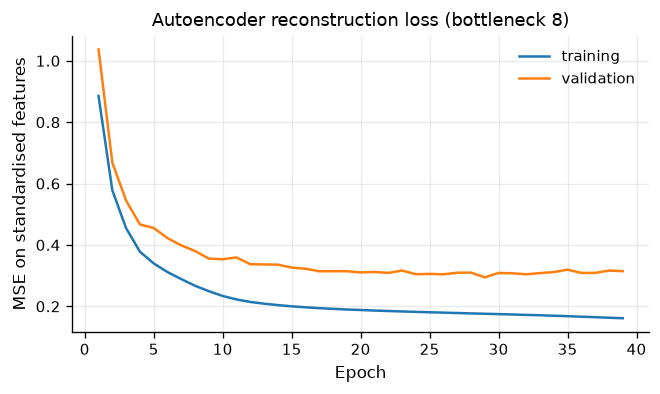

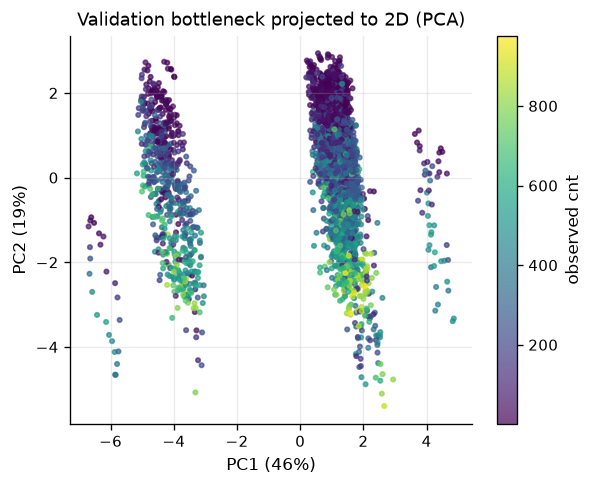

In [6]:
# reconstruction loss per epoch: training and validation
hist = models[best_b]["ae_history"]
fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.plot(hist["epoch"], hist["train_loss"], label="training")
ax.plot(hist["epoch"], hist["val_loss"], label="validation")
ax.set(title=f"Autoencoder reconstruction loss (bottleneck {best_b})",
       xlabel="Epoch", ylabel="MSE on standardised features")
ax.legend()
bc.save_figure(fig, "fig_ae_loss_curve.png")
plt.show()

from sklearn.decomposition import PCA
# 2D view of the bottleneck, coloured by the observed count
pca = PCA(n_components=2, random_state=SEED)
Z2 = pca.fit_transform(encode(best_ae, Xva))
fig, ax = plt.subplots(figsize=(5.4, 4.2))
sc = ax.scatter(Z2[:, 0], Z2[:, 1], c=yva, s=7, cmap="viridis", alpha=0.7)
ax.set(title="Validation bottleneck projected to 2D (PCA)",
       xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})",
       ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
fig.colorbar(sc, ax=ax, label="observed cnt")
bc.save_figure(fig, "fig_ae_latent_pca.png")
plt.show()

**Model comparison.** Diagnostics for the AE model, then validation and test MAE for the autoencoder, the raw-feature MLP and ridge.


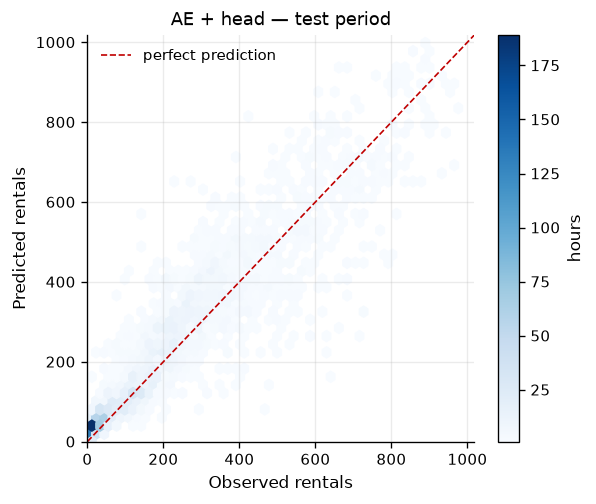

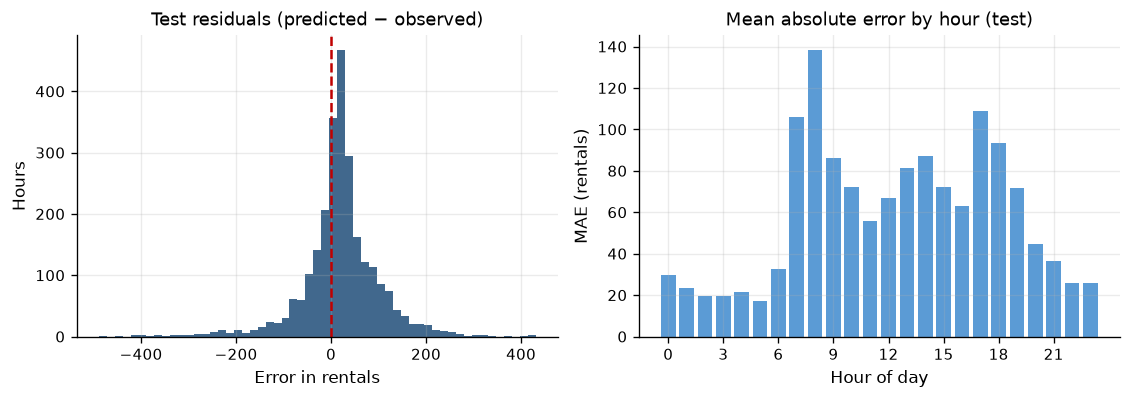

Residual mean 19.78 | standard deviation 83.31


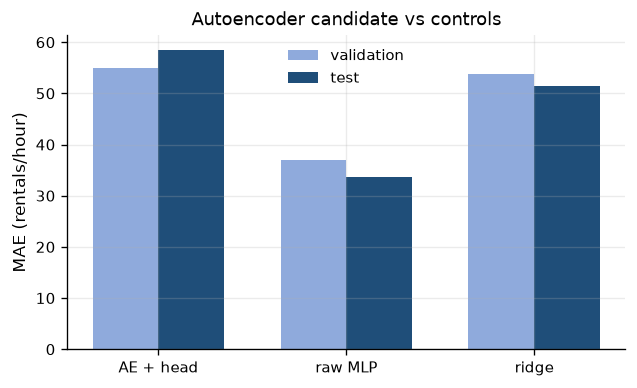

In [7]:
# residuals and peak-hour behaviour for the AE model
bc.plot_diagnostics(yte, ae_test_pred, d["test"]["hr"], "AE + head", "ae")

# validation vs test MAE for the three candidates
fig, ax = plt.subplots(figsize=(6.0, 3.4))
pos, width = np.arange(3), 0.35
ax.bar(pos - width / 2, [metrics[n]["validation"]["MAE"] for n in preds], width,
       label="validation", color="#8faadc")
ax.bar(pos + width / 2, [metrics[n]["test"]["MAE"] for n in preds], width,
       label="test", color="#1f4e79")
ax.set_xticks(pos, list(preds))
ax.set(title="Autoencoder candidate vs controls", ylabel="MAE (rentals/hour)")
ax.legend()
bc.save_figure(fig, "fig_ae_comparison.png")
plt.show()

## 6. Cost and saved evidence
Only the encoder and head are needed to predict; the decoder is discarded.

In [8]:
# save encoder and head separately; the decoder is not needed at inference
encoder_path, head_path = bc.MODELS_DIR / "ae_encoder.pt", bc.MODELS_DIR / "ae_head.pt"
torch.save(best_ae.encoder.state_dict(), encoder_path)
torch.save(best_head.state_dict(), head_path)
# encoder plus head latency on the full test set
latency = bc.measure_inference(ae_predict, Xte, repeats=5)
print(f"Encoder + head {bc.file_mb(encoder_path, head_path):.3f} MB | "
      f"single row {latency['single_row_ms']:.3f} ms")

# predictions and configuration for notebook 5
bc.save_predictions(d["test"], ae_test_pred, "pred_ae_test.csv")
bc.save_predictions(d["validation"], ae_val_pred, "pred_ae_validation.csv")
config = {"bottleneck": best_b, "hidden": 16, "head_hidden": 32, "features": d["feature_names"],
          "target_mean": y_mean, "target_std": y_std, "seed": SEED}
bc.save_json(config, "ae_config.json")
# metrics record, including both controls and the negative-result flag
bc.save_json({
    "method": "Autoencoder + regression head", "owner": "Zongliang Han", "lab": "Lab 8",
    "config": config, "bottleneck_search": bottleneck_table.to_dict(orient="records"), **ev,
    "controls": {n.lower().replace(" ", "_"): metrics[n] for n in ("raw MLP", "ridge")},
    "negative_result": bool(ae_val_mae >= raw_mae),
    "ae_train_seconds": float(best_row["ae_seconds"]),
    "head_train_seconds": float(best_row["head_seconds"]),
    "model_size_mb": bc.file_mb(encoder_path, head_path), "inference": latency,
    "train_rows": int(len(ytr)),
}, "ae_metrics.json")
print("Saved results/ae_metrics.json, prediction CSVs and models/ae_encoder.pt / ae_head.pt")

Encoder + head 0.008 MB | single row 0.160 ms
Saved results/ae_metrics.json, prediction CSVs and models/ae_encoder.pt / ae_head.pt


## 7. Conclusion
* The raw-feature MLP beats AE + head: compressing 23 features into a small
  bottleneck optimised for *reconstruction* throws away signal the
  *regression* needs. This is a documented negative result.
* The AE is by far the smallest and fastest model, but accuracy decides here.
* The controls turn "representation learning should help" into a test.

## Appendix — shared code used by this notebook

Source of every `bike_common.py` function and constant this notebook uses, copied from the module for reading. These cells are display-only, so the outputs above are unchanged.

Called directly in this notebook: `evaluate`, `file_mb`, `measure_inference`, `plot_diagnostics`, `predict_regressor`, `prepare_tabular`, `regression_metrics`, `save_figure`, `save_json`, `save_predictions`, `scenario_table`, `setup_plot_style`, `train_regressor`, `MODELS_DIR`, `SEED`.  
Helpers they rely on: `find_data_dir`, `load_raw`, `load_split_files`, `build_design_matrix`, `FeatureScaler`, `build_hourly_grid`, `peak_hours`, `high_demand_threshold`, `scenario_metrics`, `fmt_metrics`.

**Constants**

```python
DATA_DIR = find_data_dir()
PROJECT_DIR = DATA_DIR / "project"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"
MODELS_DIR = PROJECT_DIR / "models"
RAW_COLUMNS = [
    "instant", "dteday", "season", "yr", "mnth", "hr", "holiday", "weekday",
    "workingday", "weathersit", "temp", "atemp", "hum", "windspeed",
    "casual", "registered", "cnt",
]
TARGET = "cnt"
BASE_FEATURE_COLUMNS = [
    "season_1", "season_2", "season_3",
    "weather_1", "weather_2", "weather_3",
    "mnth_sin", "mnth_cos",
    "hr_sin", "hr_cos",
    "wd_sin", "wd_cos",
    "holiday", "workingday",
    "temp", "atemp", "hum", "windspeed",
]
HISTORY_COLUMNS = ["lag1", "lag24", "lag168", "roll24", "roll168"]
FEATURE_COLUMNS = BASE_FEATURE_COLUMNS + HISTORY_COLUMNS
WARMUP_HOURS = 168
MIN_POSITION = 2 * WARMUP_HOURS - 1
SCALE_COLUMNS = FEATURE_COLUMNS[:]
SEED = 42
META_COLUMNS = ["instant", "dteday", "hr", "weekday", "workingday",
                "season", "weathersit", "cnt"]
```

**`find_data_dir`**

```python
def find_data_dir(start: Path | str | None = None) -> Path:
    """Walk upwards from *start* (then from this file) until hour.csv is found."""
    here = Path(start or Path.cwd()).resolve()
    module_dir = Path(__file__).resolve().parent
    for candidate in (here, *here.parents, module_dir, *module_dir.parents):
        if (candidate / "hour.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find hour.csv in this folder or any parent folder. "
        "Run the notebook from inside the AI project directory."
    )
```

**`load_raw`**

```python
def load_raw() -> pd.DataFrame:
    """Load hour.csv with a parsed date and a proper datetime index column."""
    df = pd.read_csv(DATA_DIR / "hour.csv", parse_dates=["dteday"])
    df["dt"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")
    return df
```

**`load_split_files`**

```python
def load_split_files() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Load the frozen chronological train / validation / test splits."""
    parts = {}
    for name in ("train", "validation", "test"):
        part = pd.read_csv(DATA_DIR / f"{name}.csv", parse_dates=["dteday"])
        part["dt"] = part["dteday"] + pd.to_timedelta(part["hr"], unit="h")
        parts[name] = part
    return parts["train"], parts["validation"], parts["test"]
```

**`build_design_matrix`**

```python
def build_design_matrix(frame: pd.DataFrame) -> pd.DataFrame:
    """
    Turn raw calendar + weather columns into the 18 shared model features.

    Encodings:
      * season and weathersit are one-hot encoded, with the last level
        (season 4 / weathersit 4) as the reference category.
      * month, hour and weekday are encoded cyclically (sin/cos) so that
        23:00 is close to 00:00 and December is close to January.
      * holiday and workingday stay as 0/1 flags.
      * temp, atemp, hum and windspeed remain numeric and are standardised
        later, using training statistics only.

    No demand-derived features (casual, registered, lagged cnt) are used.
    This keeps the input available at prediction time and avoids target
    leakage.
    """
    out = pd.DataFrame(index=frame.index)

    season = frame["season"].astype(int)
    weather = frame["weathersit"].astype(int)
    for level in (1, 2, 3):
        out[f"season_{level}"] = (season == level).astype(float)
        out[f"weather_{level}"] = (weather == level).astype(float)

    month = frame["mnth"].astype(float)
    hour = frame["hr"].astype(float)
    weekday = frame["weekday"].astype(float)

    out["mnth_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
    out["mnth_cos"] = np.cos(2 * np.pi * (month - 1) / 12)
    out["hr_sin"] = np.sin(2 * np.pi * hour / 24)
    out["hr_cos"] = np.cos(2 * np.pi * hour / 24)
    out["wd_sin"] = np.sin(2 * np.pi * weekday / 7)
    out["wd_cos"] = np.cos(2 * np.pi * weekday / 7)

    out["holiday"] = frame["holiday"].astype(float)
    out["workingday"] = frame["workingday"].astype(float)

    for col in ("temp", "atemp", "hum", "windspeed"):
        out[col] = frame[col].astype(float)

    return out[BASE_FEATURE_COLUMNS]
```

**`FeatureScaler`**

```python
class FeatureScaler:
    """Standardise features using training rows only (no leakage)."""

    def __init__(self) -> None:
        self.scaler = StandardScaler()
        self.fitted = False

    def fit(self, X: pd.DataFrame) -> "FeatureScaler":
        self.scaler.fit(X)
        self.fitted = True
        return self

    def transform(self, X: pd.DataFrame) -> np.ndarray:
        if not self.fitted:
            raise RuntimeError("Call fit() on the training features first.")
        return self.scaler.transform(X)

    def fit_transform(self, X: pd.DataFrame) -> np.ndarray:
        return self.fit(X).transform(X)

    def save(self, path: Path) -> None:
        import joblib

        joblib.dump(self.scaler, path)

    @classmethod
    def load(cls, path: Path) -> "FeatureScaler":
        import joblib

        obj = cls()
        obj.scaler = joblib.load(path)
        obj.fitted = True
        return obj
```

**`prepare_tabular`**

```python
def prepare_tabular() -> dict:
    """
    Load the frozen splits and return scaled tabular arrays plus metadata.

    Every model notebook calls this function, so the train/validation/test
    rows, the shared feature set and the scaling are identical across the four
    methods.

    The first two weeks of the dataset are discarded for *all* methods.  The
    first week is needed before ``lag168``/``roll168`` exist; the second week
    is needed so that a full 168-hour sliding window contains no warm-up NaNs.
    Validation and test start long after this point, so they are unaffected.
    """
    train, val, test = load_split_files()
    grid = build_hourly_grid()
    positions = {name: grid.index.get_indexer(part["dt"])
                 for name, part in
                 (("train", train), ("validation", val), ("test", test))}

    def collect(part: pd.DataFrame, pos: np.ndarray):
        frame = grid.iloc[pos][FEATURE_COLUMNS].reset_index(drop=True)
        mask = (pos >= MIN_POSITION) & frame.notna().all(axis=1).to_numpy()
        return (part.loc[mask].reset_index(drop=True),
                frame.loc[mask].reset_index(drop=True),
                pos[mask])

    train, Xtr_raw, ptr = collect(train, positions["train"])
    val, Xva_raw, pva = collect(val, positions["validation"])
    test, Xte_raw, pte = collect(test, positions["test"])

    scaler = FeatureScaler().fit(Xtr_raw)
    return {
        "train": train,
        "validation": val,
        "test": test,
        "positions": {"train": ptr, "validation": pva, "test": pte},
        "X_train": scaler.transform(Xtr_raw),
        "X_validation": scaler.transform(Xva_raw),
        "X_test": scaler.transform(Xte_raw),
        "X_train_raw": Xtr_raw,
        "X_validation_raw": Xva_raw,
        "X_test_raw": Xte_raw,
        "y_train": train[TARGET].to_numpy(dtype=float),
        "y_validation": val[TARGET].to_numpy(dtype=float),
        "y_test": test[TARGET].to_numpy(dtype=float),
        "scaler": scaler,
        "feature_names": FEATURE_COLUMNS,
    }
```

**`build_hourly_grid`**

```python
def build_hourly_grid(raw: pd.DataFrame | None = None) -> pd.DataFrame:
    """
    Reindex the data onto a complete hourly grid and fill the 165 missing
    hours using *past-only* forward fill.

    The UCI export has 165 missing hours (0.95%).  Calendar fields are rebuilt
    exactly from the timestamp; date-level fields come from a daily table;
    weather fields are forward-filled.  No future value is used, so sliding
    windows built on this grid remain causal.

    Returns a frame indexed by datetime with raw columns, the shared design
    matrix columns, and the target (NaN where the hour was not observed).
    """
    if raw is None:
        raw = load_raw()

    full_hours = pd.date_range(raw["dt"].min(), raw["dt"].max(), freq="h")
    max_date = (full_hours.max() + pd.Timedelta(days=1)).normalize()
    full_days = pd.date_range(raw["dt"].min().normalize(), max_date - pd.Timedelta(days=1), freq="D")

    daily = (
        raw.groupby("dteday")
        .agg(season=("season", "first"), yr=("yr", "first"),
             holiday=("holiday", "max"), workingday=("workingday", "max"))
        .reindex(full_days)
        .ffill()
    )
    # The first date is always present, so ffill fully covers the range.

    weather = (
        raw.set_index("dt")[["weathersit", "temp", "atemp", "hum", "windspeed"]]
        .reindex(full_hours)
        .ffill()
    )
    # The target is *not* forward-filled: a missing hour stays missing so that
    # it can never become a training or evaluation sample.
    target = raw.set_index("dt")["cnt"].reindex(full_hours)

    grid = pd.DataFrame(index=full_hours)
    grid["dteday"] = grid.index.normalize()
    grid["mnth"] = grid.index.month
    grid["hr"] = grid.index.hour
    grid["weekday"] = (grid.index.dayofweek + 1) % 7  # UCI: Sunday=0
    grid = grid.join(daily, on="dteday")
    grid = grid.join(weather)
    grid["cnt"] = target
    grid["season"] = grid["season"].astype(int)
    grid["holiday"] = grid["holiday"].astype(int)
    grid["workingday"] = grid["workingday"].astype(int)
    grid["weathersit"] = grid["weathersit"].astype(int)

    design = build_design_matrix(grid)
    for col in BASE_FEATURE_COLUMNS:
        grid[col] = design[col].to_numpy()

    # Causal demand history.  cnt is forward-filled first (so a missing hour
    # inherits the last observed demand), then every feature is shifted so that
    # it only ever contains information from earlier hours.
    demand = grid["cnt"].ffill()
    grid["lag1"] = demand.shift(1)
    grid["lag24"] = demand.shift(24)
    grid["lag168"] = demand.shift(168)
    grid["roll24"] = demand.shift(1).rolling(24, min_periods=24).mean()
    grid["roll168"] = demand.shift(1).rolling(168, min_periods=168).mean()

    grid["observed"] = grid["cnt"].notna()
    return grid
```

**`regression_metrics`**

```python
def regression_metrics(y_true, y_pred) -> dict:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
        "mean_error": float(np.mean(y_pred - y_true)),
    }
```

**`peak_hours`**

```python
def peak_hours(train: pd.DataFrame, fraction: float = 0.25) -> list[int]:
    """Hours whose average training demand is in the top *fraction*."""
    profile = train.groupby("hr")["cnt"].mean().sort_values(ascending=False)
    n = max(1, int(round(len(profile) * fraction)))
    return sorted(int(h) for h in profile.head(n).index)
```

**`high_demand_threshold`**

```python
def high_demand_threshold(train: pd.DataFrame, quantile: float = 0.75) -> float:
    return float(train["cnt"].quantile(quantile))
```

**`scenario_metrics`**

```python
def scenario_metrics(meta: pd.DataFrame, y_true, y_pred,
                     train: pd.DataFrame) -> dict:
    """
    Break the test error down by the scenarios the report discusses.
    ``meta`` must contain hr, weekday and workingday for the evaluated rows.
    """
    meta = meta.reset_index(drop=True)
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    abs_err = np.abs(y_pred - y_true)

    peak = set(peak_hours(train))
    threshold = high_demand_threshold(train)
    is_peak = meta["hr"].isin(peak).to_numpy()
    is_weekend = (meta["workingday"] == 0).to_numpy()
    is_high = y_true >= threshold

    result = {}
    for name, mask in {
        "peak_hours": is_peak,
        "off_peak_hours": ~is_peak,
        "weekday": ~is_weekend,
        "weekend_or_holiday": is_weekend,
        "high_demand": is_high,
        "lower_demand": ~is_high,
    }.items():
        result[name] = {
            "n": int(mask.sum()),
            "MAE": float(abs_err[mask].mean()) if mask.any() else None,
            "RMSE": float(np.sqrt(np.mean((y_pred[mask] - y_true[mask]) ** 2)))
            if mask.any() else None,
        }

    by_hour = (
        pd.DataFrame({"hr": meta["hr"].to_numpy(), "abs_err": abs_err})
        .groupby("hr")["abs_err"].agg(["mean", "count"])
        .rename(columns={"mean": "MAE", "count": "n"})
    )
    result["by_hour"] = {
        int(h): {"MAE": float(row["MAE"]), "n": int(row["n"])}
        for h, row in by_hour.iterrows()
    }
    return result
```

**`measure_inference`**

```python
def measure_inference(model_predict, X, repeats: int = 5) -> dict:
    """Measure single-row and batch inference latency on this machine."""
    X = np.asarray(X)
    model_predict(X[:2])  # warm-up
    t0 = time.perf_counter()
    for _ in range(repeats):
        model_predict(X)
    batch = (time.perf_counter() - t0) / repeats

    t0 = time.perf_counter()
    for i in range(min(200, len(X))):
        model_predict(X[i:i + 1])
    single = (time.perf_counter() - t0) / min(200, len(X))
    return {
        "batch_seconds": float(batch),
        "batch_rows": int(len(X)),
        "single_row_ms": float(single * 1000),
    }
```

**`save_json`**

```python
def save_json(obj, name: str, directory: Path | None = None) -> Path:
    directory = directory or RESULTS_DIR
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / name
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(obj, fh, indent=2, ensure_ascii=False)
    return path
```

**`setup_plot_style`**

```python
def setup_plot_style() -> None:
    """Consistent, readable matplotlib defaults for every notebook."""
    import matplotlib as mpl

    mpl.rcParams.update({
        "figure.dpi": 120,
        "savefig.dpi": 160,
        "figure.figsize": (7.2, 4.2),
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "legend.frameon": False,
        "font.size": 9,
    })
```

**`save_figure`**

```python
def save_figure(fig, name: str, directory: Path | None = None) -> Path:
    directory = directory or FIGURES_DIR
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / name
    fig.savefig(path, bbox_inches="tight")
    return path
```

**`fmt_metrics`**

```python
def fmt_metrics(metrics: dict) -> str:
    return (f"MAE {metrics['MAE']:.2f} | RMSE {metrics['RMSE']:.2f} | "
            f"R2 {metrics['R2']:.4f}")
```

**`train_regressor`**

```python
def train_regressor(model_fn, X_train, y_train, X_val, y_val, y_mean, y_std, *,
                    max_epochs=15, patience=4, lr=1e-3, batch_size=128,
                    clip=True, use_scheduler=True, tag="model", verbose=True):
    """
    Train a PyTorch regressor on the standardised target with early stopping.

    ``model_fn`` builds the network after the seed is set, so every run starts
    from the same weights.  The loop uses AdamW, smooth L1 loss, optional
    gradient clipping and an optional ReduceLROnPlateau scheduler; it stops
    when validation MAE (in rentals) has not improved by 0.05 for ``patience``
    epochs and restores the best epoch's weights.
    """
    import copy
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset

    torch.manual_seed(SEED)
    model = model_fn()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = (torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)
                 if use_scheduler else None)
    loss_fn = nn.SmoothL1Loss(beta=0.5)

    Xtr = torch.tensor(np.asarray(X_train, dtype=np.float32))
    ytr = torch.tensor((np.asarray(y_train) - y_mean) / y_std, dtype=torch.float32).view(-1, 1)
    Xva = torch.tensor(np.asarray(X_val, dtype=np.float32))
    yva = torch.tensor((np.asarray(y_val) - y_mean) / y_std, dtype=torch.float32).view(-1, 1)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))

    history, best_mae, best_epoch, bad = [], float("inf"), 0, 0
    best_state = copy.deepcopy(model.state_dict())
    t0 = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        model.train()
        running = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            if clip:
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(Xtr)

        model.eval()
        with torch.no_grad():
            val_scaled = model(Xva)
            val_loss = loss_fn(val_scaled, yva).item()
        val_mae = regression_metrics(y_val, val_scaled.numpy().ravel() * y_std + y_mean)["MAE"]
        if scheduler is not None:
            scheduler.step(val_loss)
        history.append({"epoch": epoch, "train_loss": train_loss,
                        "val_loss": val_loss, "val_MAE": val_mae})
        if verbose:
            print(f"{tag} epoch {epoch:02d}  train {train_loss:.4f}  "
                  f"val {val_loss:.4f}  val MAE {val_mae:.2f}", flush=True)

        if val_mae < best_mae - 0.05:
            best_mae, best_epoch, bad = val_mae, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                print(f"{tag}: early stop at epoch {epoch} "
                      f"(best epoch {best_epoch}, MAE {best_mae:.2f})")
                break

    model.load_state_dict(best_state)
    model.eval()
    return {"model": model, "history": pd.DataFrame(history), "best_epoch": best_epoch,
            "best_val_MAE": best_mae, "train_seconds": time.perf_counter() - t0}
```

**`predict_regressor`**

```python
def predict_regressor(model, X, y_mean, y_std):
    """Predict rentals per hour with a trained PyTorch regressor."""
    import torch

    model.eval()
    with torch.no_grad():
        scaled = model(torch.tensor(np.asarray(X, dtype=np.float32))).numpy().ravel()
    return scaled * y_std + y_mean
```

**`evaluate`**

```python
def evaluate(y_val, val_pred, y_test, test_pred, meta_val, meta_test, train) -> dict:
    """Overall and scenario metrics on validation and test, printed and returned."""
    out = {
        "validation": regression_metrics(y_val, val_pred),
        "test": regression_metrics(y_test, test_pred),
        "validation_scenarios": scenario_metrics(meta_val, y_val, val_pred, train),
        "test_scenarios": scenario_metrics(meta_test, y_test, test_pred, train),
        "peak_hours": peak_hours(train),
        "high_demand_threshold": high_demand_threshold(train),
    }
    print("Validation:", fmt_metrics(out["validation"]))
    print("Test:      ", fmt_metrics(out["test"]))
    return out
```

**`scenario_table`**

```python
def scenario_table(ev: dict) -> pd.DataFrame:
    """Scenario MAE table (validation and test) from :func:`evaluate`."""
    val, test = ev["validation_scenarios"], ev["test_scenarios"]
    keys = [k for k in val if k != "by_hour"]
    return pd.DataFrame({
        "validation n": {k: val[k]["n"] for k in keys},
        "validation MAE": {k: val[k]["MAE"] for k in keys},
        "test n": {k: test[k]["n"] for k in keys},
        "test MAE": {k: test[k]["MAE"] for k in keys},
    }).round(2)
```

**`plot_diagnostics`**

```python
def plot_diagnostics(y_true, y_pred, hours, title: str, prefix: str) -> None:
    """Predicted-vs-observed hexbin, residual histogram and MAE by hour (test)."""
    import matplotlib.pyplot as plt

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    hb = ax.hexbin(y_true, y_pred, gridsize=45, cmap="Blues", mincnt=1)
    lims = [0, max(y_true.max(), y_pred.max()) * 1.02]
    ax.plot(lims, lims, color="#c00000", ls="--", lw=1, label="perfect prediction")
    ax.set(xlim=lims, ylim=lims, xlabel="Observed rentals", ylabel="Predicted rentals",
           title=f"{title} — test period")
    ax.legend(loc="upper left")
    fig.colorbar(hb, ax=ax, label="hours")
    save_figure(fig, f"fig_{prefix}_pred_vs_actual.png")
    plt.show()

    residual = y_pred - y_true
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
    axes[0].hist(residual, bins=55, color="#1f4e79", alpha=0.85)
    axes[0].axvline(0, color="#c00000", ls="--")
    axes[0].set(title="Test residuals (predicted − observed)",
                xlabel="Error in rentals", ylabel="Hours")
    by_hour = pd.Series(np.abs(residual)).groupby(np.asarray(hours)).mean()
    axes[1].bar(by_hour.index, by_hour.values, color="#5b9bd5")
    axes[1].set(title="Mean absolute error by hour (test)",
                xlabel="Hour of day", ylabel="MAE (rentals)")
    axes[1].set_xticks(range(0, 24, 3))
    plt.tight_layout()
    save_figure(fig, f"fig_{prefix}_residuals.png")
    plt.show()
    print(f"Residual mean {residual.mean():.2f} | standard deviation {residual.std():.2f}")
```

**`save_predictions`**

```python
def save_predictions(meta: pd.DataFrame, y_pred, name: str) -> None:
    """Write one prediction CSV keyed by ``instant`` for the comparison notebook."""
    frame = meta.reset_index(drop=True)[[c for c in META_COLUMNS if c in meta]].copy()
    frame["prediction"] = np.asarray(y_pred)
    frame.to_csv(RESULTS_DIR / name, index=False)
```

**`file_mb`**

```python
def file_mb(*paths) -> float:
    return sum(Path(p).stat().st_size for p in paths) / (1024 * 1024)
```